In [1]:
# NIM: 202431004 - Dzaky rahman Ikhsan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.linear_model import LinearRegression


In [2]:
# NIM: 202431004 - Dzaky rahman Ikhsan
# Load Dataset
df = pd.read_csv("02_diabetes.csv")
df.head()


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


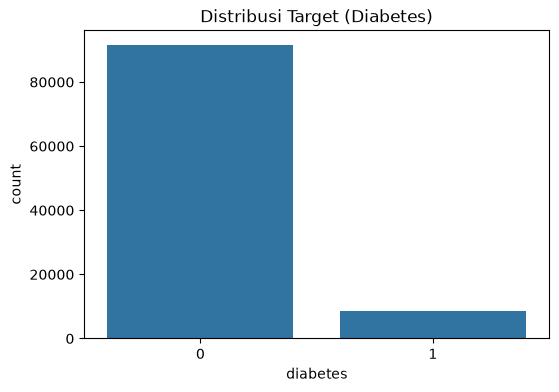

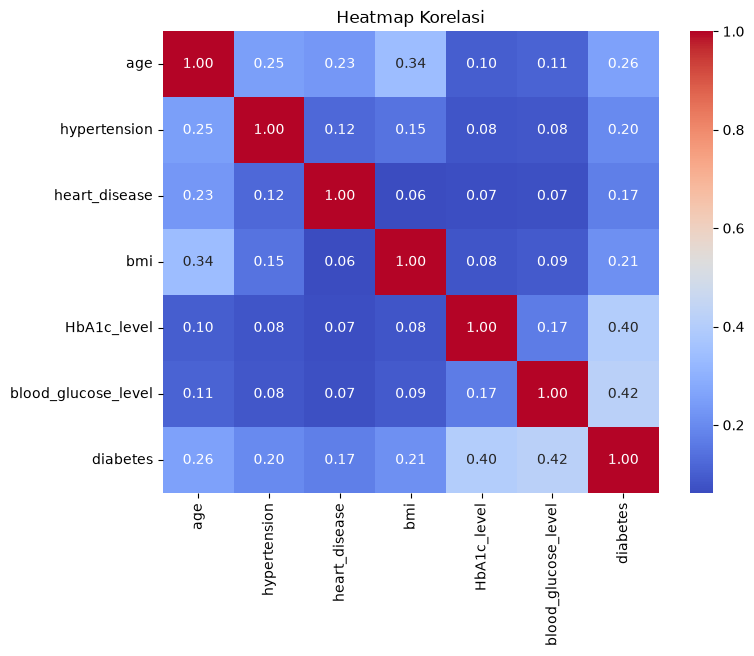

In [3]:
# NIM: 202431004 - Dzaky rahman Ikhsan
# Simple EDA & Visualization
plt.figure(figsize=(6,4))
sns.countplot(data=df, x='diabetes')
plt.title('Distribusi Target (Diabetes)')
plt.show()

# Melihat korelasi antar fitur numerik
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Heatmap Korelasi')
plt.show()


In [4]:
# NIM: 202431004 - Dzaky rahman Ikhsan
# Preprocessing Data
df_clean = df.copy()

# Encoding data kategorikal (gender, smoking_history)
le = LabelEncoder()
df_clean['gender'] = le.fit_transform(df_clean['gender'])
df_clean['smoking_history'] = le.fit_transform(df_clean['smoking_history'])

# Memisahkan fitur dan target
X = df_clean.drop('diabetes', axis=1)
y = df_clean['diabetes']

# Scaling data agar skala seragam
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [5]:
# NIM: 202431004 - Dzaky rahman Ikhsan
# Membagi data menjadi training dan testing (80:20)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)
print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))


Jumlah data latih: 80000
Jumlah data uji: 20000


In [6]:
# NIM: 202431004 - Dzaky rahman Ikhsan
# Modeling - Regresi Linear
model = LinearRegression()
model.fit(X_train, y_train)

# Prediksi (karena regresi, hasil berupa nilai kontinu)
y_pred_cont = model.predict(X_test)

# Thresholding 0.5 untuk mengubah ke bentuk biner (klasifikasi)
y_pred = (y_pred_cont >= 0.5).astype(int)


Akurasi Model Regresi Linear: 93.86%


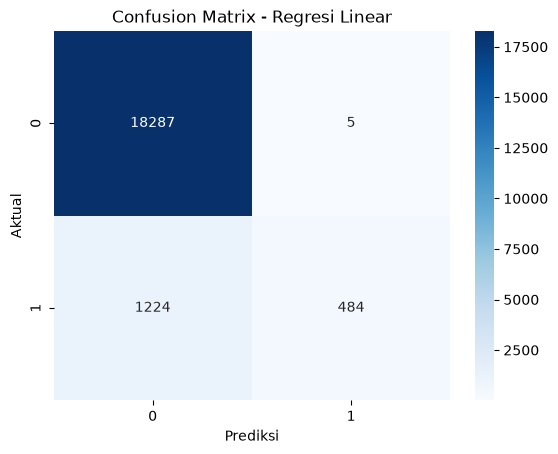

In [9]:
# NIM: 202431004 - Dzaky rahman Ikhsan
# Evaluasi Model
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi Model Regresi Linear: {akurasi * 100:.2f}%")

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Regresi Linear')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()